In [1]:
import pandas as pd

df = pd.read_csv('long_091826.csv')

In [2]:
plot_df = df.pivot(index='peptide', columns='individual', values='z_score')

In [3]:
prefix_sl = ("C-", "S-")

cols = sorted([c for c in plot_df.columns if c.startswith(prefix_sl)])

cols_other = [c for c in plot_df.columns if c not in cols]

new_order = cols + cols_other

plot_df = plot_df[new_order]

In [4]:
plot_df.head(2)

individual,C-109-1_5_B3,C-109-2_5_B5,C-109-3_4_E7,C-110-1_2_A5,C-110-2_3_F8,C-110-3_2_E6,C-111-1_2_H8,C-111-2_3_I5,C-111-3_3_I6,C-112-1_3_B3,...,HBDB-097,HBDB-098,HBDB-099,HBDB-100,HBDB-102,HBDB-106,HBDB-107,HBDB-109,HBDB-111,HBDB-115
peptide,,,,,,,,,,,,,,,,,,,,,
AAA16239.1|polypeptide|Orthohantavirus_thailandense|isolate=?|?|?|?|segment=?|strain=Thai749|tile_41,0.057732,0.243062,-0.607326,-1.365708,-1.365708,0.775374,-1.365708,3.674863,-0.195965,0.181786,...,1.349044,1.718223,-0.080548,-0.195472,-1.388853,0.023754,-0.685725,-0.058794,0.436547,0.637975
AAA47458.1|?|sandfly_fever_Sicilian_virus|isolate=?|?|?|?|segment=?|strain=?|tile_9,0.059172,0.164990,1.320591,0.249751,-1.744803,-1.744803,0.076687,1.558030,0.386355,0.850987,...,-0.699830,0.948390,-0.122927,-1.535288,-1.051778,2.084602,1.119610,-0.011119,-0.356824,1.395405


/data1/sporak/anaconda3/envs/align3/lib/python3.10/site-packages/seaborn/matrix.py:1113: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  self._figure.tight_layout(**tight_params)


<Figure size 1000x1000 with 0 Axes>

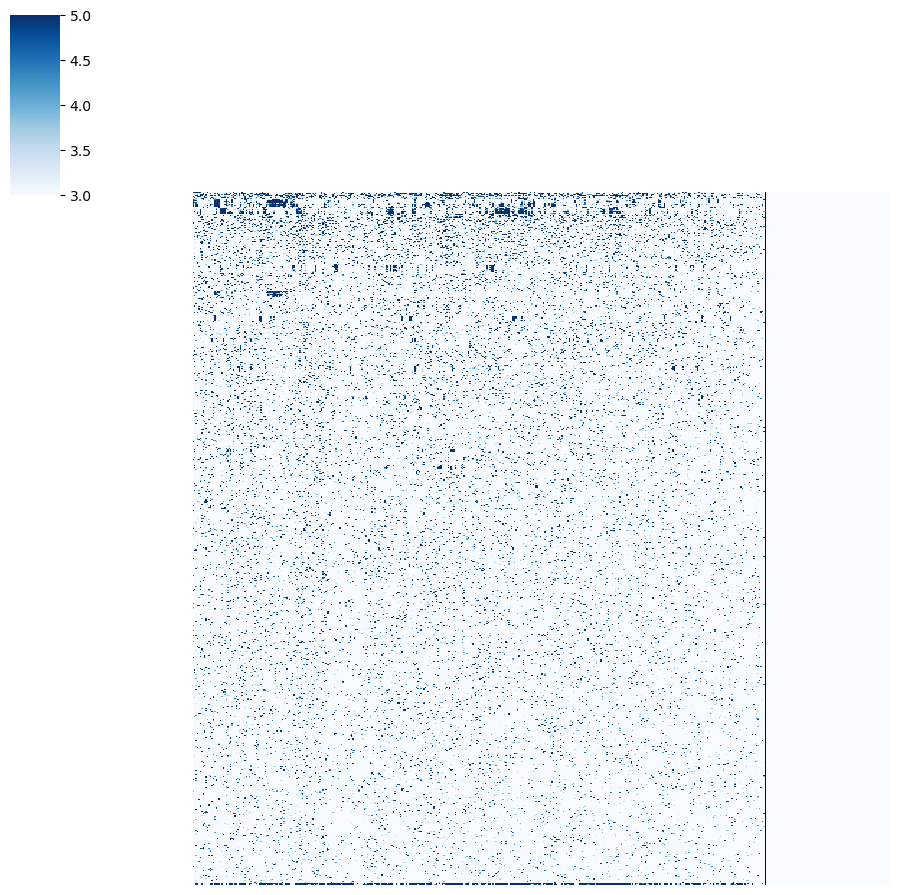

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 10))

g = sns.clustermap(plot_df, annot=False, row_cluster=True, col_cluster=True, cmap="Blues", vmin=3, vmax=5, dendrogram_ratio=0.01)

g.ax_heatmap.set_xticklabels([])
g.ax_heatmap.set_yticklabels([])

g.ax_row_dendrogram.set_visible(False)
g.ax_col_dendrogram.set_visible(False)

g.ax_heatmap.axis('off')

g.ax_heatmap.axvline(x=len(cols), color='black', linestyle="-", linewidth=0.7)

plt.show()

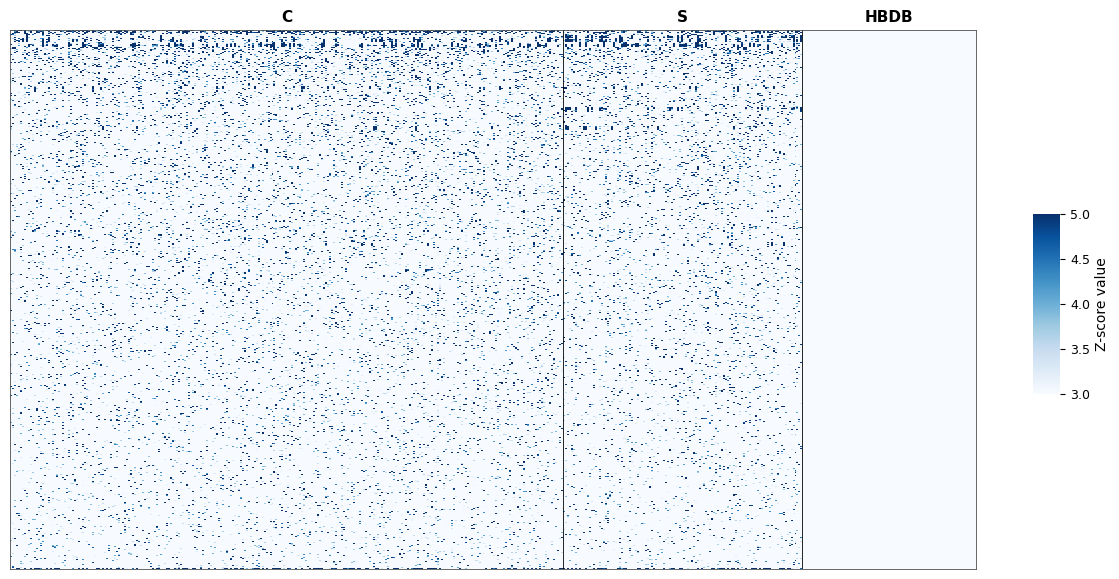

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

n_c = sum(c.startswith("C-") for c in plot_df.columns)
n_cs = len(cols)  # all C- and S- columns

g = sns.clustermap(
    plot_df,
    row_cluster=True,
    col_cluster=False,          # keep C- | S- | other order
    cmap="Blues",
    vmin=3, vmax=5,
    figsize=(11, 6),
    dendrogram_ratio=(0.08, 0.02),
    cbar_pos=(1.02, 0.35, 0.025, 0.3),   # right side, vertically centered
    cbar_kws={"label": "Z-score value", "ticks": [3, 3.5, 4, 4.5, 5]},
    xticklabels=False, yticklabels=False,
    rasterized=True,            # keeps PDF/SVG small with many cells
)

g.ax_row_dendrogram.set_visible(False)
ax = g.ax_heatmap
ax.set_xlabel(""); ax.set_ylabel("")

# group dividers
for x in (n_c, n_cs):
    ax.axvline(x, color="black", lw=0.6)

# group labels on top
groups = [("C", 0, n_c), ("S", n_c, n_cs), ("HBDB", n_cs, plot_df.shape[1])]
for name, start, end in groups:
    if end > start:
        ax.text((start + end) / 2, -0.01 * plot_df.shape[0], name,
                ha="center", va="bottom", fontsize=11, fontweight="bold")

# thin frame around the heatmap
for spine in ax.spines.values():
    spine.set_visible(True); spine.set_linewidth(0.6); spine.set_color("0.3")

g.cax.tick_params(labelsize=9)
g.cax.yaxis.label.set_size(10)

g.savefig("heatmap.svg", format='svg', bbox_inches="tight")
plt.show()

In [7]:
reordered_indices = g.dendrogram_row.reordered_ind
cluster_row_names = plot_df.index[reordered_indices]

cluster_row_names

Index(['XQH02928.1|protein|Tick_phlebovirus|isolate=XJ4ST/2022|Rhipicephalus_turanicus|China:_Bachu-_Xinjiang|2022|segment=S|strain=?|tile_7',
       'YP_009346018.1|polyprotein|Ambe_virus|isolate=?|Phlebotominae_sp.|Brazil|14-Jan-1982|segment=M|strain=BeAr407981|tile_57',
       'YP_010086097.1|precursor|Cacao_virus|isolate=VP-437R|Nyssomyia_trapidoi|Panama:_El_Aguacate|04-Dec-1970|segment=M|strain=?|tile_53',
       'ABI96821.1|protein|Mammarenavirus_choriomeningitidis|?|?|?|?|L|CH-5692|tile_3',
       'YP_010840000.1|polymerase|Meram_virus|isolate=M1|Hyalomma_aegyptium|Turkey|22-May-2017|segment=?|strain=?|tile_36',
       'XNX24835.1|precursor|Nairobi_sheep_disease_virus|isolate=21P-ST|Haemaphysalis_longicornis|China:_Shandong-_Weifang|2021|segment=M|strain=?|tile_4',
       'WRI50013.1|polymerase|Norwavirus_sp.|isolate=?|Ixodes_ricinus|Bulgaria|?|segment=?|strain=p80|tile_19',
       'YP_010839955.1|glycoprotein|Salmon_pescarenavirus_1|G518|Oncorhynchus_tshawytscha|Canada:_Dawley_

In [8]:
len(cluster_row_names)

1287